# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
# TODO 1
n_voxels = 512 * 512 * 300
scan_mb = n_voxels * 2 / 1024**2                 # 16 bits = 2 bytes per voxel

# TODO 2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)    # (x, y, z) in mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
rays = 512 * 300                                  # one ray per x-z pixel
samples_per_frame = rays * 512                    # 512 samples per ray along y
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")


78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_

Two things go wrong. First, the shape is distorted: coronal and sagittal slices contain the z axis, and the voxels are twice as thick in z as in x and y, so if the software treats them as square pixels the head looks squashed to half its true height and round structures look like ovals. Second, all measurements taken from the slices (distances, lesion size, and any volume computed with the wrong voxel size) would be wrong by a factor of 2 along z, which matters for surgical planning. The fix is to set the display aspect ratio from the voxel spacing (as done with ASPECT) or resample to isotropic voxels.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

1 candidate components; lesion = 431 voxels; centroid (z, y, x) = (28, 40, 41)


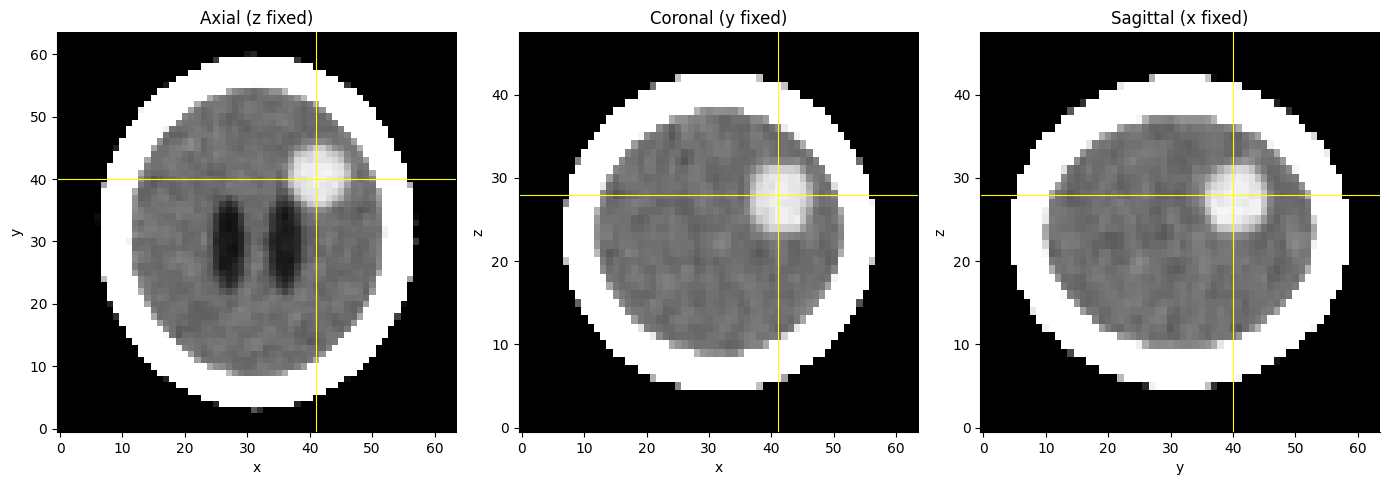

Centroid error vs ground truth: 2.92 mm


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1: soft-tissue-range voxels that lie inside the brain (no labels used)
skull = vol > 300
inside = ndimage.binary_fill_holes(skull) & ~skull
inside = ndimage.binary_erosion(inside, iterations=3)
candidates = (vol > 55) & (vol < 90) & inside

# TODO 2: largest connected component and its centroid
lab, n = ndimage.label(candidates)
sizes = ndimage.sum(candidates, lab, index=np.arange(1, n + 1))
lesion = lab == (np.argmax(sizes) + 1)
cz, cy, cx = [int(round(v)) for v in ndimage.center_of_mass(lesion)]
print(f"{n} candidate components; lesion = {int(sizes.max())} voxels; centroid (z, y, x) = ({cz}, {cy}, {cx})")

# TODO 3: axial / coronal / sagittal through the centroid
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
views = [
    ("Axial (z fixed)",    vol[cz, :, :], None,   (cx, cy), "x", "y"),
    ("Coronal (y fixed)",  vol[:, cy, :], ASPECT, (cx, cz), "x", "z"),
    ("Sagittal (x fixed)", vol[:, :, cx], ASPECT, (cy, cz), "y", "z"),
]
for ax, (title, sl, asp, (px_, py_), xl, yl) in zip(axes, views):
    ax.imshow(window(sl, 80, 40), cmap="gray", origin="lower", aspect=asp or 1)
    ax.axvline(px_, color="yellow", lw=0.8); ax.axhline(py_, color="yellow", lw=0.8)
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl)
plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
tz, ty, tx_ = [v for v in ndimage.center_of_mass(labels == 5)]
err_mm = np.sqrt(((cz - tz) * SPACING[0])**2 + ((cy - ty) * SPACING[1])**2 + ((cx - tx_) * SPACING[2])**2)
print(f"Centroid error vs ground truth: {err_mm:.2f} mm")


**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_

Voxels on the border between brain (about 35 HU) and the skull (about 700 HU) contain a mixture of both materials, so by the partial-volume effect their averaged value passes through the 55-90 HU range, which is exactly the tumour range. This is the overlapping-intensity problem of Slide 28: a HU window alone cannot tell "tumour" from "blurred edge between brain and bone", so thresholding alone gives a false thin shell under the skull. Eroding the brain mask 3 times removes the layer next to the bone, so only voxels deep inside the brain are kept and the largest component is the real lesion (the trade-off is that a tumour touching the skull could be trimmed).

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold,voxels,volume_mL,dice
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


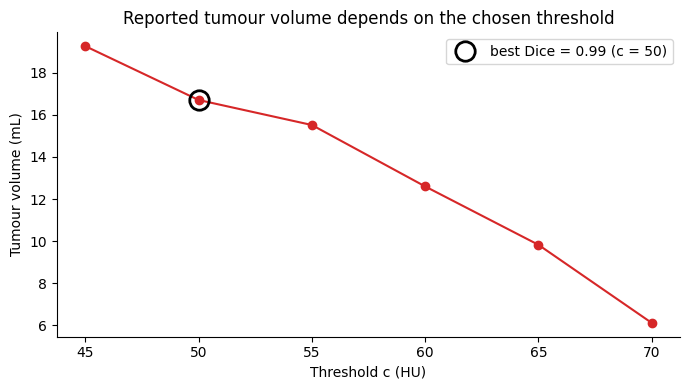

Report to surgeon: 6.12 - 19.26 mL (best-Dice threshold 50 HU -> 16.70 mL; true volume 16.70 mL)


In [4]:
truth = labels == 5
rows = []
# TODO 1 & 2
for c in [45, 50, 55, 60, 65, 70]:
    lab_c, _ = ndimage.label(vol > c)
    seg = lab_c == lab_c[cz, cy, cx]                  # component containing the lesion centre
    n = int(seg.sum())
    dice = 2 * (seg & truth).sum() / (seg.sum() + truth.sum())
    rows.append({"threshold": c, "voxels": n, "volume_mL": n * VOXEL_MM3 / 1000, "dice": dice})


table = pd.DataFrame(rows)
display(table)

# TODO 3
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table.threshold, table.volume_mL, "-o", color="tab:red")
best = table.loc[table.dice.idxmax()]
ax.plot(best.threshold, best.volume_mL, "o", ms=14, mfc="none", mec="k", mew=2,
        label=f"best Dice = {best.dice:.2f} (c = {best.threshold:.0f})")
ax.set_xlabel("Threshold c (HU)"); ax.set_ylabel("Tumour volume (mL)")
ax.set_title("Reported tumour volume depends on the chosen threshold"); ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
print(f"Report to surgeon: {table.volume_mL.min():.2f} - {table.volume_mL.max():.2f} mL "
      f"(best-Dice threshold {best.threshold:.0f} HU -> {best.volume_mL:.2f} mL; true volume {truth.sum() * VOXEL_MM3 / 1000:.2f} mL)")


**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_

Without ground truth I would choose c at the half-way point between the typical intensity of normal brain (about 36 HU) and of the tumour (about 68 HU), which is about 50 HU, i.e. where the edge is steepest, and confirm it by checking that the volume is stable around that value (the curve changes least for c around 45-55 HU) and that the contour hugs the visible edge on the MPR slices. I would show the uncertainty instead of one number: report a range (here about 6 to 19 mL, with the most plausible values near 15-17 mL), draw several nested contours or isosurfaces for different thresholds (semi-transparent shells or colour-coded outlines on the slices), and show the volume-versus-threshold plot so the surgeon can see how sensitive the number is.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

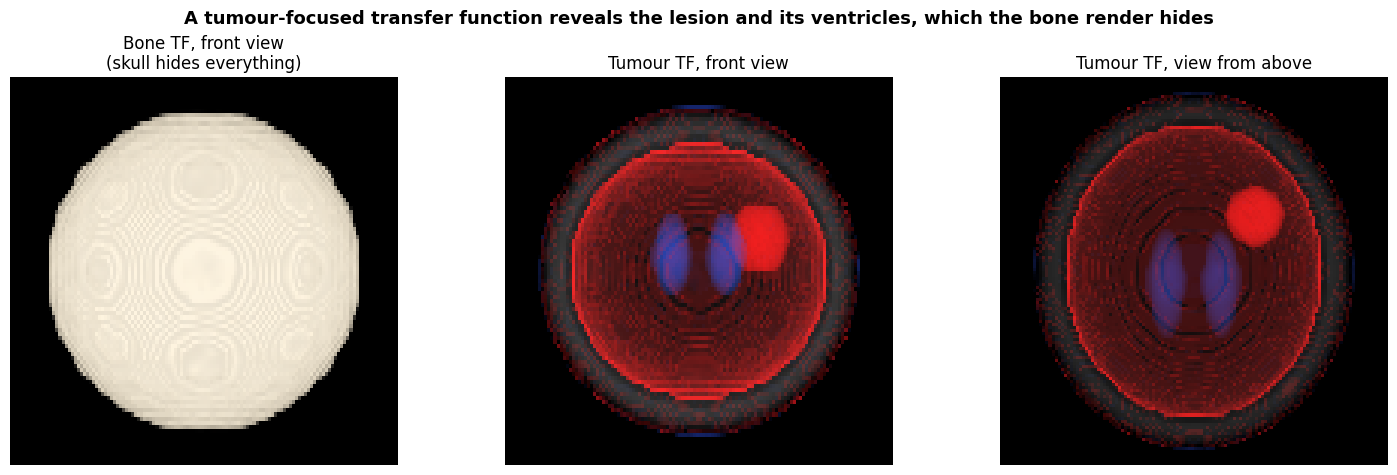

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
BLUE, RED = (0.2, 0.35, 1.0), (1.0, 0.1, 0.1)
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0),      # air: transparent
    (-100,  (0, 0, 0), 0.0),
    (2,     BLUE,      0.0),      # CSF: faint blue (thin ventricles stay faint, thick ones accumulate)
    (5,     BLUE,      0.03),
    (20,    BLUE,      0.03),
    (25,    (0, 0, 0), 0.0),      # soft tissue (~35 HU): fully transparent
    (48,    (0, 0, 0), 0.0),
    (55,    RED,       0.12),     # tumour: red
    (80,    RED,       0.12),
    (90,    RED,       0.0),
    (300,   (0, 0, 0), 0.0),
    (440,   (0.9, 0.9, 0.9), 0.004),   # bone: almost transparent, just for context
    (1500,  (1, 1, 1), 0.008),
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render | your TF front view | your TF top view
def show(ax, vol_, tf, axis, title):
    C, A = render(vol_, tf, axis=axis)
    img_ = np.clip(C, 0, 1)                       # black background
    asp = ASPECT if axis == 1 else 1              # z is on screen for the front view
    ax.imshow(img_, origin="lower", aspect=asp); ax.set_title(title); ax.axis("off")

show(axes[0], vol, bone_tf, 1, "Bone TF, front view\n(skull hides everything)")
show(axes[1], vol, tumour_tf, 1, "Tumour TF, front view")
show(axes[2], vol, tumour_tf, 0, "Tumour TF, view from above")

# TODO 4: suptitle
fig.suptitle("A tumour-focused transfer function reveals the lesion and its ventricles, which the bone render hides", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()


**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_

The faint red rim is caused by the partial-volume effect and the overlapping intensity ranges of Slide 28: blurred voxels at the brain/skull boundary have HU values in the tumour range, so the transfer function colours them red. A technique that would remove it is segmentation (Slides 31-32), for example region growing or a connected component from the tumour seed, or masking/clipping to the brain interior, and then rendering only that segmented region. A transfer function alone cannot do it because it is a function of the intensity value only: a boundary voxel and a real tumour voxel with the same HU get exactly the same colour and opacity, and separating them needs spatial information (connectivity and position), which segmentation provides.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_

The lesion is a roughly spherical mass, off-centre and close to the ventricles, deep inside the brain tissue (centre at voxel z=28, y=40, x=41), and its volume is somewhere between about 6 and 19 mL depending on the threshold, with the best-supported estimate near 16-17 mL (about 15.5-16.7 mL for thresholds of 50-55 HU). I recommend opening the meeting with the three-plane MPR (with the segmentation outline on it), because slicing exposes the internal structure without occlusion, the voxel aspect ratio keeps the anatomy undistorted, and segmentation is what makes the volume measurable. The 3-D render is useful for showing the relation to the ventricles, but the board should remember its limitation: it depends on the transfer function, intensity overlap creates false structures such as the faint rim under the skull, and nothing in it is measured, so it should not be used for sizing.